# EDA — Predicción genómica de rendimiento en maíz

Fase 1 — Análisis exploratorio. Genotipos binarios (SNPs) + fenotipos
(GY, PH, AD) en dos ambientes (Optimal/Drought), campañas CIMMYT 2017–2020
(Lopez-Cruz et al.). Régimen *p >> n*.

> Todo el EDA se hace sobre el dev (2017–2019). El año 2020 es el test final y queda sellado hasta la evaluación de cierre.

Objetivo: cerrar dos decisiones — (1) protocolo de validación,
(2) filtros de preprocesamiento.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / 'data' / 'Geno_data.csv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.loader import load_dataset
from src.eda import eda

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
DEV_YEARS = (2017, 2018, 2019)
TEST_YEAR = 2020
YEAR_COLORS = {2017: '#1f77b4', 2018: '#ff7f0e', 2019: '#2ca02c'}
TARGETS = ('GY', 'PH', 'AD'); ENVS = ('Optimal', 'Drought')
print('repo root:', ROOT)

repo root: C:\Users\sanca\Desktop\UdeSA\Tercer Año\ML\PF\maze-genomic-pred


In [2]:
ds = load_dataset(str(ROOT / 'data' / 'Geno_data.csv'),
                  str(ROOT / 'data' / 'Pheno_data.csv'))
geno = pd.read_csv(ROOT / 'data' / 'Geno_data.csv')
pheno_full = ds.pheno.copy()
X_full = ds.G
gid_full = ds.gid_index.astype(str)
year_of = dict(zip(pheno_full['GID'].astype(str), pheno_full['Year']))
years_full = np.array([year_of[g] for g in gid_full])

DEV = years_full < TEST_YEAR
X, gid, years = X_full[DEV], gid_full[DEV], years_full[DEV]
pheno = pheno_full[pheno_full['Year'] < TEST_YEAR].copy()
print('dev (analizable): X', X.shape, '| años', dict(zip(*np.unique(years, return_counts=True))))
print('test 2020 SELLADO:', int((~DEV).sum()), 'líneas (no se analizan)')

dev (analizable): X (3042, 4612) | años {np.int64(2017): np.int64(901), np.int64(2018): np.int64(1419), np.int64(2019): np.int64(722)}
test 2020 SELLADO: 486 líneas (no se analizan)


## 1. Shapes, dtypes y valores faltantes

Chequeo de integridad. Reportamos los tamaños totales (gestión de datos, no
análisis) y todo lo distribucional solo sobre dev.

In [3]:
ov = eda.overview(geno, pheno_full)
print(ov.to_string(index=False))
print('\nSolapamiento de GID  ->  solo geno:', ov.attrs['gid_geno_only'],
      '| solo pheno:', ov.attrs['gid_pheno_only'], '| en ambos:', ov.attrs['gid_both'])
print('Líneas por campaña:', dict(zip(*np.unique(years_full, return_counts=True))),
      ' (2020 = test sellado)')

qc = eda.genotype_qc_values(X)
print('\nGenotipo dev: faltantes =', qc['n_missing'],
      '| valores únicos =', qc['valores_unicos'],
      '| binaria {0,1}? =', qc['es_binaria_01'])

     tabla  filas  columnas_datos  GID_unicos
 Geno_data   3528            4612        3528
Pheno_data   3528               6        3528

Solapamiento de GID  ->  solo geno: 0 | solo pheno: 0 | en ambos: 3528
Líneas por campaña: {np.int64(2017): np.int64(901), np.int64(2018): np.int64(1419), np.int64(2019): np.int64(722), np.int64(2020): np.int64(486)}  (2020 = test sellado)



Genotipo dev: faltantes = 0 | valores únicos = [0, 1] | binaria {0,1}? = True


In [4]:
print(eda.phenotype_missingness(pheno).to_string())
print('\nCada GID pertenece a un único año:',
      (pheno.groupby('GID')['Year'].nunique() == 1).all())

            faltantes    pct
GY_Optimal          1  0.033
PH_Optimal          1  0.033
AD_Optimal          1  0.033
GY_Drought          2  0.066
PH_Drought          2  0.066
AD_Drought          2  0.066

Cada GID pertenece a un único año: True


3528 líneas × 4612 SNPs en total; de ellas 3042 son dev
(2017–2019) y 486 son el test 2020 sellado. Join genotipo<->fenotipo perfecto. La
matriz de SNPs es estrictamente binaria `{0,1}` y sin faltantes. En fenotipo
hay 1–2 celdas faltantes por columna (<0.07 % del dev), todas en dev, que se
descartan al armar cada target (`dropna` por bloque en el loader; no se imputan).
Cada `GID` está en un solo año => ninguna línea cruza años.

## 2. QC de SNPs: monomórficos y distribución de MAF -> filtro

> QC de SNPs (*quality control*): los chequeos y filtros que limpian la matriz
> de marcadores antes de modelar — faltantes por SNP (*call rate*), SNPs
> monomórficos (sin variación -> no informan) y filtro de MAF.
>
> SNP (*Single Nucleotide Polymorphism*): posición del genoma donde la base de
> ADN varía entre líneas. Cada columna es un SNP con dos alelos, codificados `{0,1}`.
>
> MAF (*Minor Allele Frequency*): frecuencia del alelo minoritario de un SNP.
> Si `f` = frecuencia del alelo '1', `MAF = min(f, 1−f)` ∈ [0, 0.5]. SNPs con MAF muy
> baja aportan poca señal y meten ruido -> se filtran (umbral usual 0.01–0.05).
> Si `MAF = 0` significa que el SNP es monomórfico. 

Calculado solo sobre dev (no se mira la frecuencia alélica de 2020).

In [5]:
maf = eda.maf(X)
print('SNPs monomórficos en dev (MAF = 0):', eda.monomorphic_count(X))
print('MAF dev -> min: %.4f | mediana: %.4f | max: %.4f' % (maf.min(), np.median(maf), maf.max()))
print()
print('Cuántos SNPs se descartan por umbral de MAF (dev):')
print(eda.maf_filter_summary(maf, (0.0, 0.01, 0.05, 0.10)).to_string(index=False))

SNPs monomórficos en dev (MAF = 0): 0
MAF dev -> min: 0.0329 | mediana: 0.2738 | max: 0.5000

Cuántos SNPs se descartan por umbral de MAF (dev):
 umbral_maf  descartados  conservados  pct_descartado
       0.00            0         4612           0.000
       0.01            0         4612           0.000
       0.05            7         4605           0.152
       0.10          148         4464           3.209


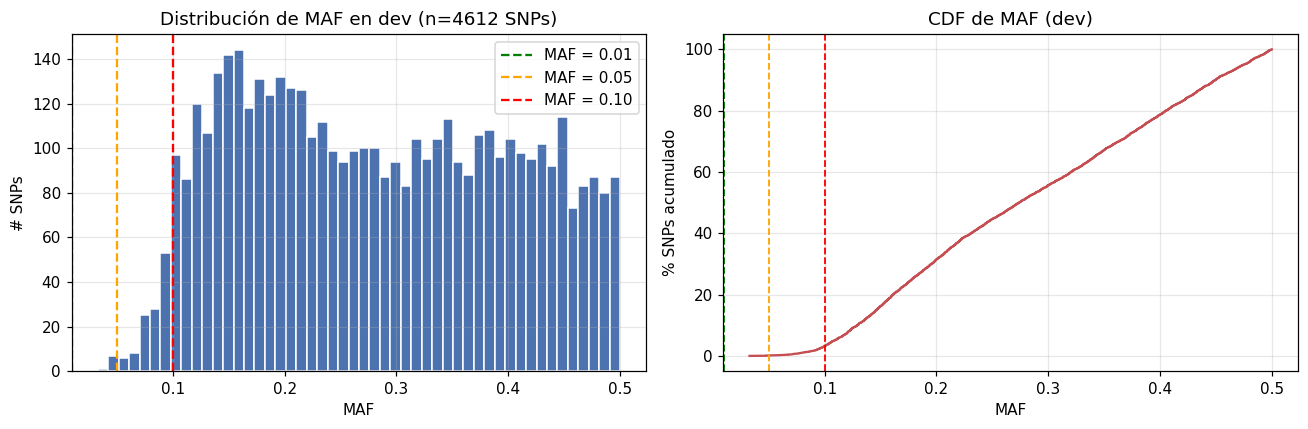

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(maf, bins=50, color='#4c72b0', edgecolor='white')
for t, c in [(0.01, 'green'), (0.05, 'orange'), (0.10, 'red')]:
    ax[0].axvline(t, color=c, ls='--', lw=1.5, label='MAF = %.2f' % t)
ax[0].set(xlabel='MAF', ylabel='# SNPs', title='Distribución de MAF en dev (n=%d SNPs)' % len(maf))
ax[0].legend()
xs = np.sort(maf)
ax[1].plot(xs, 100 * np.arange(1, len(xs) + 1) / len(xs), color='#c44e52')
for t, c in [(0.01, 'green'), (0.05, 'orange'), (0.10, 'red')]:
    ax[1].axvline(t, color=c, ls='--', lw=1.2)
ax[1].set(xlabel='MAF', ylabel='% SNPs acumulado', title='CDF de MAF (dev)')
plt.tight_layout(); plt.show()

Lectura y decisión de filtro. Sobre dev 7 SNPs (0.15 %) caen
por debajo de 0.05.

> Decisión (filtro de MAF): umbral MAF ≥ 0.05, recalculado con el train de
> cada fold (sobre dev descarta 7 SNPs; deja 4605). Sin remoción de monomórficos
> (no hay). Subir a 0.10 sacaría 148 SNPs informativos sin razón.

## 3. Targets: distribución por año y por ambiente

GY (grain yield), PH (plant height) y AD (anthesis date), en ambiente óptimo y de
sequía. Distribución por año (dev) y shift óptimo->sequía.

In [7]:
desc = eda.target_describe_by_year(pheno)
piv = desc.pivot_table(index=['trait', 'env'], columns='Year', values='mean').round(2)
print('Media por (trait, env) y año (dev):')
print(piv.to_string())

Media por (trait, env) y año (dev):
Year             2017    2018    2019
trait env                            
AD    Drought   63.32   72.68   67.52
      Optimal   64.29   66.76   65.72
GY    Drought    3.21    3.11    2.32
      Optimal    6.02    8.04    6.37
PH    Drought  207.11  212.54  214.49
      Optimal  235.32  252.83  247.06


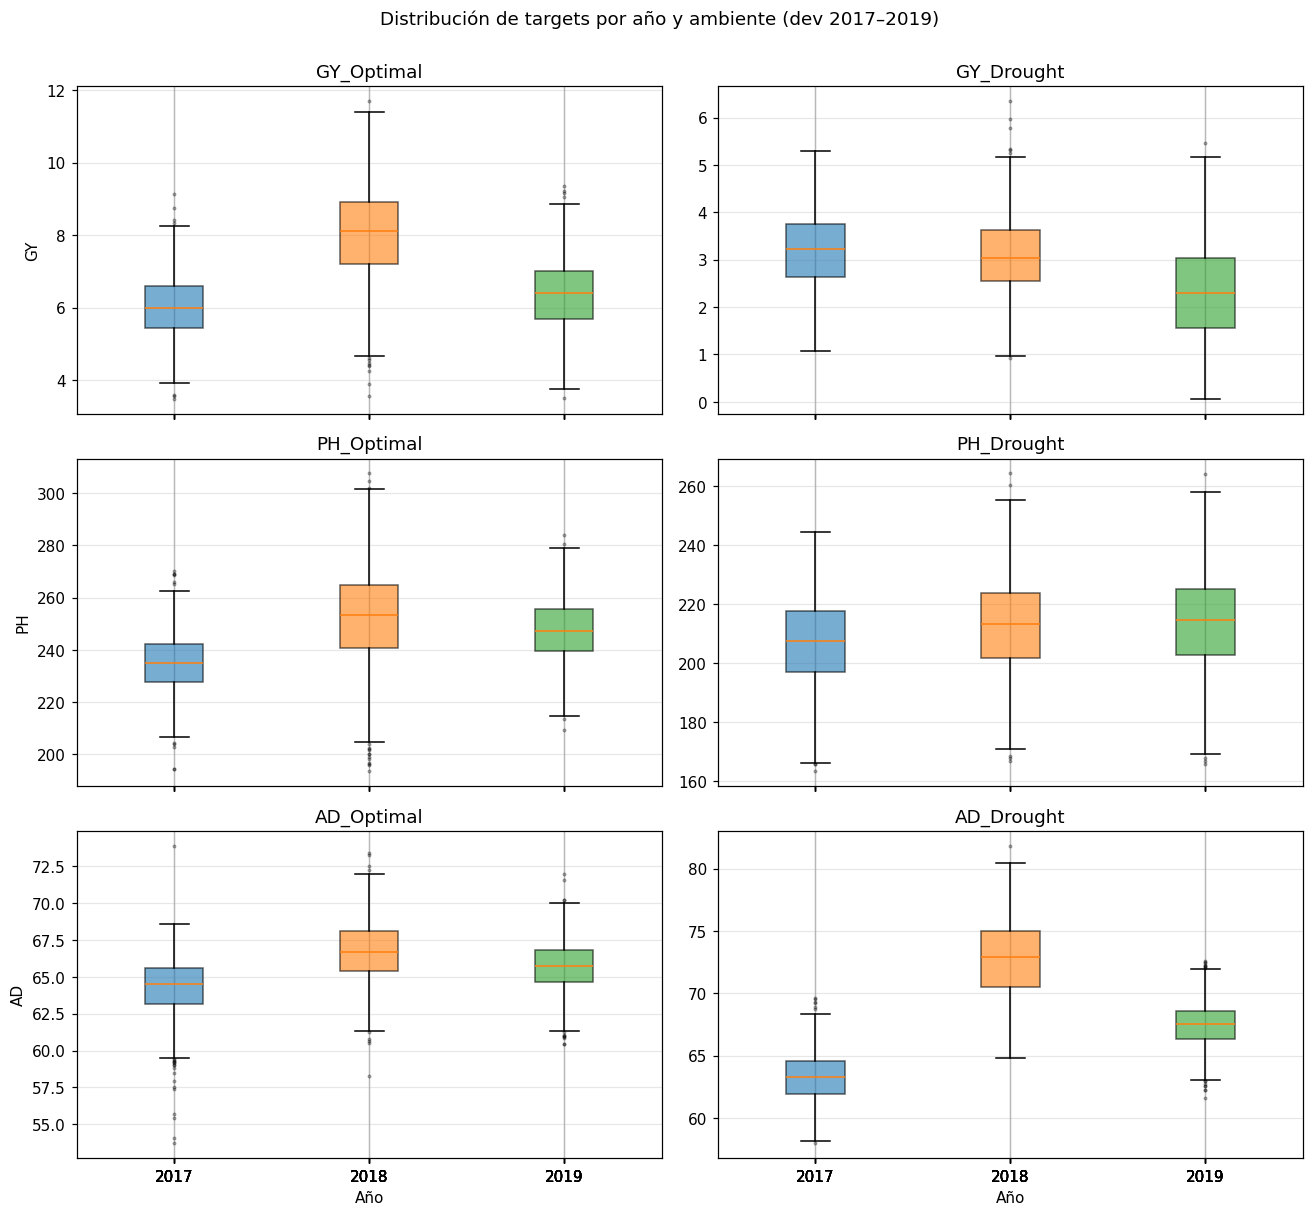

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(12, 11), sharex=True)
yrs = list(DEV_YEARS)
for r, t in enumerate(TARGETS):
    for c, e in enumerate(ENVS):
        ax = axes[r, c]; col = '%s_%s' % (t, e)
        data = [pheno.loc[pheno['Year'] == y, col].dropna().values for y in yrs]
        bp = ax.boxplot(data, tick_labels=[str(y) for y in yrs], patch_artist=True,
                        showfliers=True, flierprops=dict(marker='.', markersize=3, alpha=0.4))
        for patch, y in zip(bp['boxes'], yrs):
            patch.set_facecolor(YEAR_COLORS[y]); patch.set_alpha(0.6)
        ax.set_title(col); ax.set_ylabel(t if c == 0 else '')
axes[2, 0].set_xlabel('Año'); axes[2, 1].set_xlabel('Año')
fig.suptitle('Distribución de targets por año y ambiente (dev 2017–2019)', y=1.001)
plt.tight_layout(); plt.show()

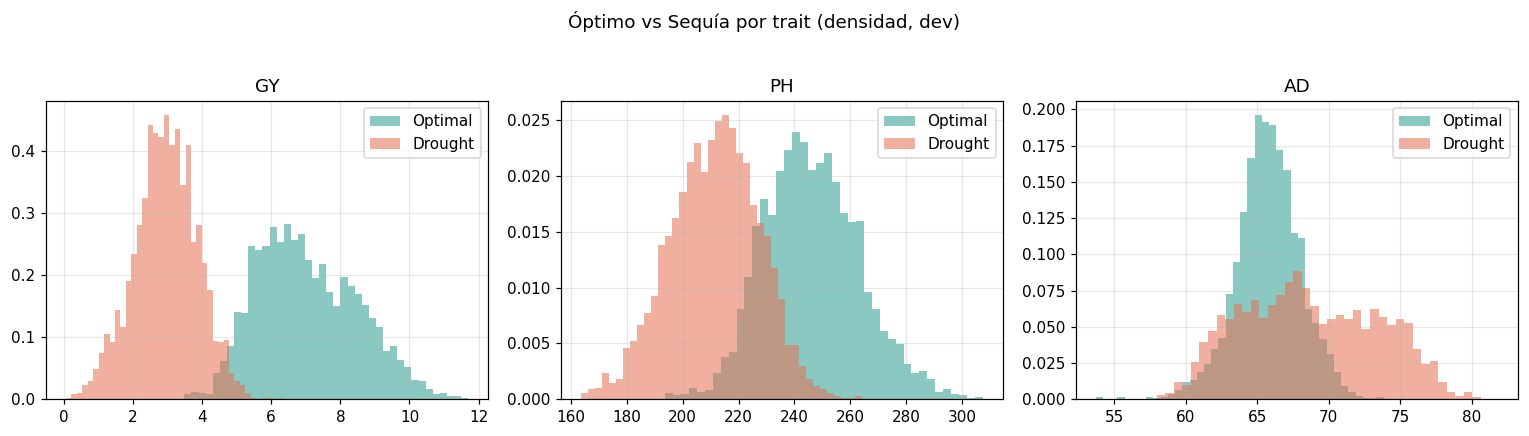

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, t in zip(axes, TARGETS):
    for e, c in zip(ENVS, ['#2a9d8f', '#e76f51']):
        s = pheno['%s_%s' % (t, e)].dropna()
        ax.hist(s, bins=40, alpha=0.55, density=True, label=e, color=c)
    ax.set_title(t); ax.legend()
fig.suptitle('Óptimo vs Sequía por trait (densidad, dev)', y=1.03)
plt.tight_layout(); plt.show()

In [10]:
print('Outliers por regla de Tukey (IQR, k=1.5) sobre dev:')
print(eda.outlier_summary(pheno).to_string(index=False))

Outliers por regla de Tukey (IQR, k=1.5) sobre dev:
    target  cota_inf  cota_sup  n_outliers  pct     max
GY_Optimal     2.675    11.371           3 0.10  11.698
PH_Optimal   199.200   292.480          27 0.89 307.570
AD_Optimal    60.372    71.258          65 2.14  73.898
GY_Drought     0.585     5.368          14 0.46   6.353
PH_Drought   168.123   255.102          15 0.49 264.390
AD_Drought    53.361    83.998           0 0.00  81.837


El estrés hídrico baja fuerte el rendimiento (GY ≈ 7.0 óptimo vs
≈ 3.0 sequía) y la altura (PH 246 vs 211). Hay efecto año marcado en las medias
(p. ej. GY óptimo salta a 8.0 en 2018): cada campaña es un ambiente distinto.
`GY_Optimal` tiene cola derecha leve (solo 3 puntos sobre la cota IQR en dev,
máx 11.7) — rendimientos altos plausibles, no errores: los conservamos y
reportamos, vigilando que Pearson (métrica de portada) es sensible a colas.

## 4. Correlación entre targets -> ¿multitarea?

(a) ¿Comparten señal GY, PH y AD dentro de un ambiente? (justifica predecir los
tres a la vez). (b) ¿El mismo trait es el mismo problema en óptimo y sequía? (GxE).
Todo sobre dev.

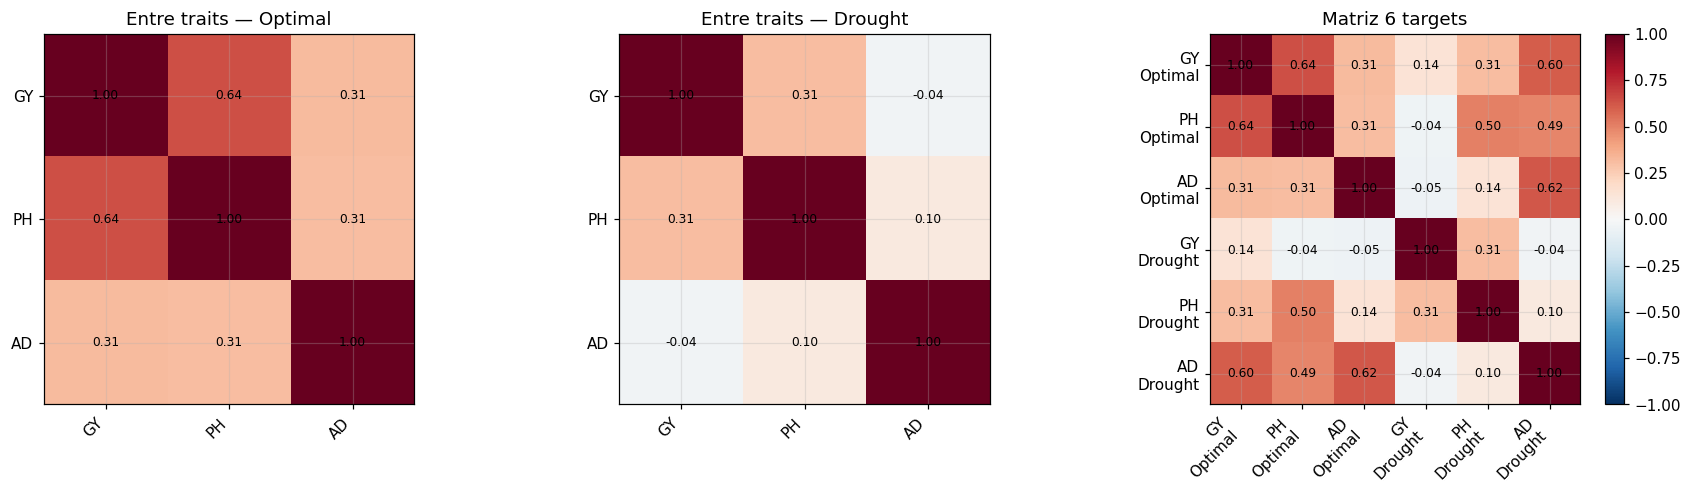

In [11]:
def heatmap(ax, M, labels, title, vmin=-1, vmax=1):
    im = ax.imshow(M, vmin=vmin, vmax=vmax, cmap='RdBu_r')
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, '%.2f' % M[i, j], ha='center', va='center', fontsize=8)
    ax.set_title(title)
    return im

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for k, e in enumerate(ENVS):
    heatmap(ax[k], eda.inter_trait_corr(pheno, e).to_numpy(), TARGETS, 'Entre traits — %s' % e)
C6 = eda.full_target_corr(pheno)
im = heatmap(ax[2], C6.to_numpy(), [c.replace('_', '\n') for c in C6.columns], 'Matriz 6 targets')
fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout(); plt.show()

In [12]:
print('Correlación del MISMO trait entre Optimal y Drought (mide GxE, dev):')
print(eda.across_env_corr(pheno).round(3).to_string())

Correlación del MISMO trait entre Optimal y Drought (mide GxE, dev):
GY    0.139
PH    0.505
AD    0.618


Dentro de un ambiente, GY correlaciona fuerte con
PH (r≈0.64 óptimo, 0.31 sequía) y débil con AD (0.31 / −0.04); PH–AD es moderada
en óptimo (0.31) y casi nula en sequía (0.10). La señal compartida está sobre todo
en el eje GY<->PH => la multitarea se justifica como regularización por tarea
auxiliar (PH auxiliar de GY) más que por redundancia de los tres. AD aporta poco
a GY.

`r(GY_Optimal, GY_Drought) = 0.14`: el rendimiento en
óptimo y en sequía es casi un trait distinto (interacción genotipo×ambiente
fuerte). PH (0.51) y AD (0.62) son más estables entre ambientes. Implicancia:
GY se predice por ambiente; apilar óptimo+sequía como un único target mezcla
dos problemas poco correlacionados.

## 5. Estructura poblacional: PCA sobre los SNPs (dev)

PCA exploratorio sobre los SNPs del dev, coloreado por año.

In [13]:
Z, evr = eda.pca_embed(X, n_components=10)
print('Varianza explicada (primeras 10 PC):', np.round(evr, 4))
print('Acumulada (10 PC): %.3f' % evr[:10].sum())
print('\nCentroide por año (PC1, PC2):')
print(eda.year_centroids(Z, years).round(2).to_string(index=False))

Varianza explicada (primeras 10 PC): [0.0634 0.051  0.0395 0.0338 0.0296 0.0248 0.0221 0.0178 0.0165 0.0145]
Acumulada (10 PC): 0.313

Centroide por año (PC1, PC2):
 Year    n   PC1   PC2
 2017  901  8.01 -0.87
 2018 1419 -4.69  0.90
 2019  722 -0.78 -0.69


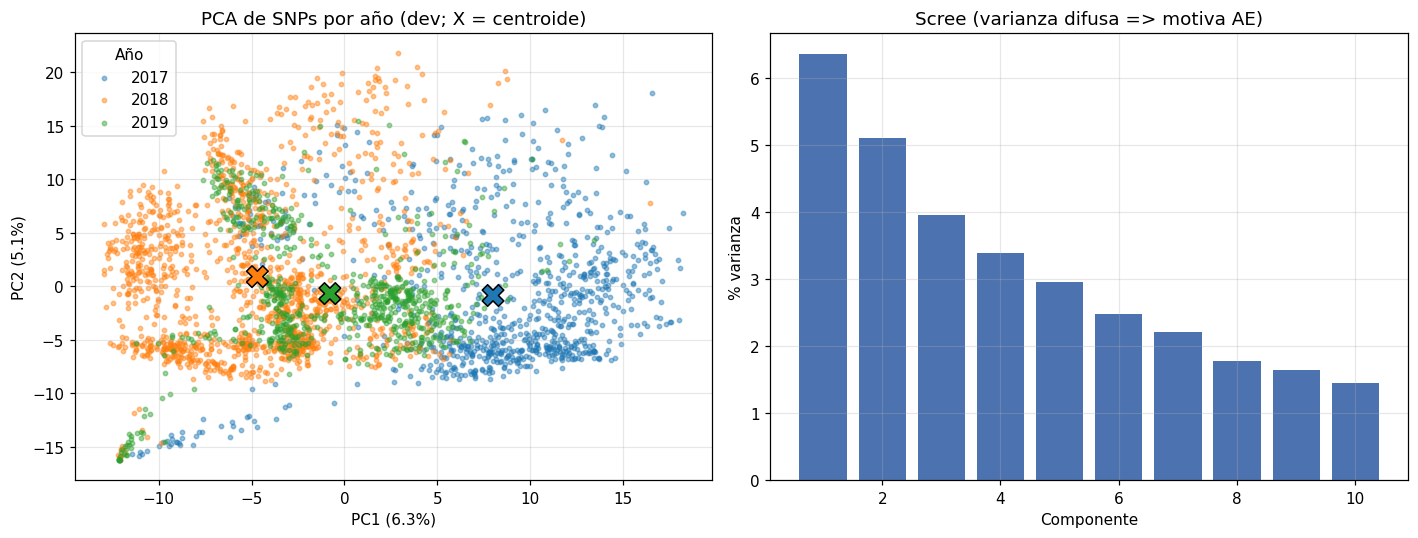

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for y in DEV_YEARS:
    m = years == y
    ax[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.45, color=YEAR_COLORS[y], label=str(y))
cent = eda.year_centroids(Z, years)
ax[0].scatter(cent['PC1'], cent['PC2'], s=200, marker='X', edgecolor='black',
              c=[YEAR_COLORS[int(y)] for y in cent['Year']], zorder=5)
ax[0].set(xlabel='PC1 (%.1f%%)' % (evr[0] * 100), ylabel='PC2 (%.1f%%)' % (evr[1] * 100),
          title='PCA de SNPs por año (dev; X = centroide)')
ax[0].legend(title='Año')
ax[1].bar(range(1, 11), evr[:10] * 100, color='#4c72b0')
ax[1].set(xlabel='Componente', ylabel='% varianza', title='Scree (varianza difusa => motiva AE)')
plt.tight_layout(); plt.show()

La varianza es muy difusa: PC1 explica ~6.3 % y las 10
primeras PC suman ~31 %. Esperado en datos genómicos poligénicos: no hay eje
dominante. Esto anticipa la extensión con autoencoder: la compresión lineal
retiene poco por componente; un AE no lineal (salida sigmoide + BCE) puede capturar
estructura que el PCA no. Aun así, los centroides de los tres años de dev se
separan netamente en PC1–PC2: la estructura poblacional está correlacionada con la
campaña. Lo cuantificamos abajo.

## 6. Drift temporal entre años de dev

¿Son los años genéticamente distintos? Separabilidad genética entre pares de
años de dev: AUC de CV de una logística sobre PCs (PCA dentro del pipeline -> sin
leakage del CV). AUC≈0.5 => años indistinguibles; AUC≈1 => cohortes distintas.

 par_de_años    n  cv_auc
2017 vs 2018 2320   0.951
2018 vs 2019 2141   0.926
2017 vs 2019 1623   0.976


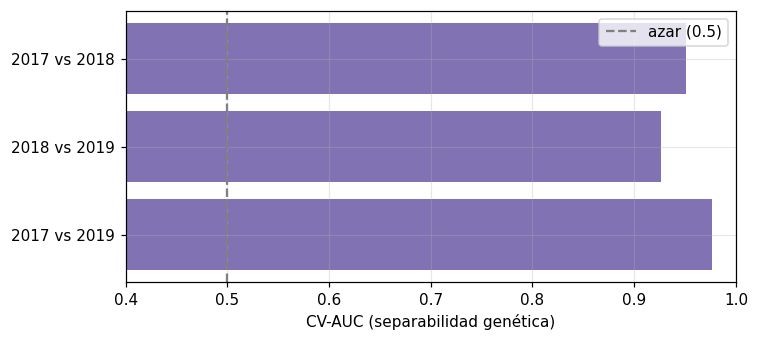

In [15]:
pairs = [(2017, 2018), (2018, 2019), (2017, 2019)]
drift = eda.drift_auc(X, years, pairs, n_pcs=20, cv=5)
print(drift.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(drift['par_de_años'], drift['cv_auc'], color='#8172b3')
ax.axvline(0.5, color='gray', ls='--', label='azar (0.5)')
ax.set(xlabel='CV-AUC (separabilidad genética)', xlim=(0.4, 1.0))
ax.invert_yaxis(); ax.legend(); plt.tight_layout(); plt.show()

El drift temporal es fuerte
ya dentro del dev: 2017 vs 2018 AUC 0.95, 2018 vs 2019 0.93, 2017 vs 2019
0.98. Cada cohorte anual es genéticamente distinguible.

1. Un CV aleatorio mezclaría años y filtraría esta estructura -> sobreestimaría
   el desempeño. La validación tiene que ser temporal.
2. Por extensión esperamos que 2020 también difiera del dev, pero no lo miramos:
   se confirma recién en el cierre. La decisión de validar temporalmente no lo
   necesita.

## 7. Relatedness y duplicados -> leakage entre splits (dev)

> IBS (*Identity By State*): similitud genética entre dos líneas = fracción de
> SNPs en los que coinciden.

Líneas emparentadas entre años de dev pueden quedar a ambos lados de la frontera
train(2017–18)/val(2019). Medimos clones exactos, NN-IBS y pares de alta identidad
cross-año (todo en dev).

In [16]:
dup = eda.exact_duplicate_groups(X)
print('Clones exactos en dev (perfil de SNPs idéntico):', dup)

ident = eda.ibs_identity_matrix(X)
nn = eda.nearest_neighbor_identity(ident, years)
print('\nNN-IBS dev — cuantiles:',
      np.round(np.quantile(nn['nn_ibs'], [0, .5, .9, .95, .99, 1]), 4))
print('NN-IBS cross-año (otro año de dev) — cuantiles:',
      np.round(np.quantile(nn['nn_ibs_cross_year'].dropna(), [0, .5, .9, .95, .99, 1]), 4))

Clones exactos en dev (perfil de SNPs idéntico): {'perfiles_unicos': 3042, 'grupos_duplicados': 0, 'lineas_en_grupos_dup': 0, 'tamaño_max_grupo': 1}



NN-IBS dev — cuantiles: [0.652  0.8797 0.9213 0.938  0.9848 0.9996]
NN-IBS cross-año (otro año de dev) — cuantiles: [0.6225 0.7579 0.8287 0.8519 0.979  0.9996]


Pares de líneas con alta identidad IBS (mismo año vs cross-año, dev):
 umbral_ibs  pares  mismo_año  cross_año
       0.90   2736       1288       1448
       0.95    939        363        576
       0.99     94         35         59

Líneas dev con un "casi-clon" (IBS>0.99) en OTRO año de dev: 16 (0.5%)


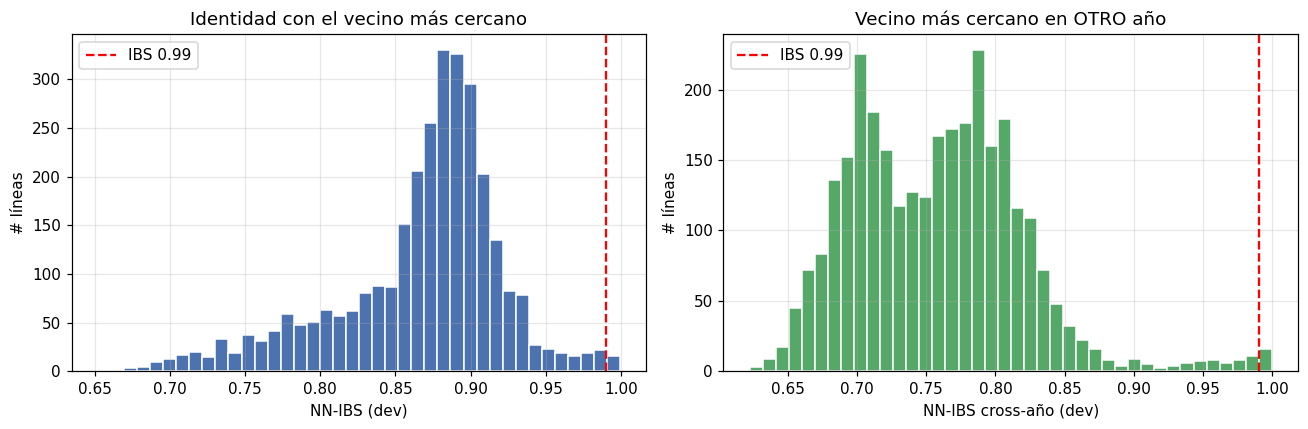

In [17]:
print('Pares de líneas con alta identidad IBS (mismo año vs cross-año, dev):')
print(eda.high_identity_pairs(ident, years, (0.90, 0.95, 0.99)).to_string(index=False))
print('\nLíneas dev con un "casi-clon" (IBS>0.99) en OTRO año de dev:',
      int((nn['nn_ibs_cross_year'] > 0.99).sum()),
      '(%.1f%%)' % (100 * (nn['nn_ibs_cross_year'] > 0.99).mean()))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(nn['nn_ibs'], bins=40, color='#4c72b0', edgecolor='white')
ax[0].axvline(0.99, color='red', ls='--', label='IBS 0.99')
ax[0].set(xlabel='NN-IBS (dev)', ylabel='# líneas', title='Identidad con el vecino más cercano')
ax[0].legend()
ax[1].hist(nn['nn_ibs_cross_year'].dropna(), bins=40, color='#55a868', edgecolor='white')
ax[1].axvline(0.99, color='red', ls='--', label='IBS 0.99')
ax[1].set(xlabel='NN-IBS cross-año (dev)', ylabel='# líneas', title='Vecino más cercano en OTRO año')
ax[1].legend(); plt.tight_layout(); plt.show()

No hay clones exactos (3042 perfiles dev únicos), pero
relatedness alta: NN-IBS mediana ≈0.88 y el 25 % de las líneas tiene un vecino
> 0.90. Cruzando años de dev: 59 pares con IBS>0.99 son cross-año y 16 líneas
(0.5 %) tienen un casi-clon en otro año de dev.

Implicancia. El split temporal no elimina del todo el parentesco a través de
la frontera train/val —inevitable en mejoramiento: las líneas de un año son
parientes de las del siguiente—. Pero es exactamente el escenario de despliegue
(predecir la campaña siguiente, emparentada con la actual). Un split aleatorio sería
peor: juntaría parientes *y* mismo año. Se acepta como realista y queda documentado.

## 8. Decisión y *lock* del protocolo de validación

| Criterio | Split fijo (train 17–18, val 19) | Forward-chaining (2 folds) |
|---|---|---|
| Analogía con el despliegue | Sí: val 2019 es el año siguiente a train (= predecir la campaña próxima) | Parcial |
| Tamaño/estabilidad del train | Máximo (2017+2018) | Un fold entrena solo con 2017, la cohorte más atípica de dev (AUC 0.95 vs 2018, 0.98 vs 2019) -> alta varianza |
| Drift entre cohortes | Validación temporal => no filtra la estructura de año | Igual, pero con un fold ruidoso |
| Líneas disjuntas | Garantizado (cada GID en un año) | Garantizado |

Forward-chaining agrega un fold entrenado solo en 2017 (la cohorte más distinta) sin
comprar robustez real con apenas 3 años. El split fijo maximiza el train, valida en
el año más reciente del dev (el análogo natural de "predecir el siguiente") y replica
el despliegue.

In [18]:
from src.eval.splits import fixed_temporal_split, final_test_split, assert_no_line_leakage

VAL_YEAR = 2019
folds = fixed_temporal_split(years_full, gid_full, val_year=VAL_YEAR, holdout_test_year=TEST_YEAR)
(tr, va), = folds
assert_no_line_leakage(tr, va, gid_full)
print('Protocolo LOCK: split temporal fijo')
print('  train =', sorted(set(years_full[tr].tolist())), ' (n=%d líneas)' % len(tr))
print('  val   =', sorted(set(years_full[va].tolist())), ' (n=%d líneas)' % len(va))
_, test_idx = final_test_split(years_full, TEST_YEAR)
print('  test  = [2020]  (n=%d líneas, SELLADO)' % len(test_idx))
print('  sin leakage de línea entre train y val: OK')

Protocolo LOCK: split temporal fijo
  train = [2017, 2018]  (n=2320 líneas)
  val   = [2019]  (n=722 líneas)
  test  = [2020]  (n=486 líneas, SELLADO)
  sin leakage de línea entre train y val: OK


## 9. Resumen de decisiones cerradas

Todo el EDA se hizo sobre dev
(2017–2019), 2020 quedó sellado.

(a) Protocolo de validación — split temporal fijo.
Train 2017–2018, validación 2019, test final 2020 . No
forward-chaining: con 3 años de dev daría un fold entrenado solo en 2017 —la cohorte
más atípica del dev (AUC 0.95–0.98 vs las otras)—, ruidoso y poco representativo. El
drift entre años de dev ya justifica la validación temporal (no hace falta mirar
2020). 2019, como año más reciente del dev, es el análogo natural de "predecir el
siguiente". El split por año da líneas disjuntas; el ~0.5 % de casi-clones cross-año
se acepta como realista. Materializado en
`fixed_temporal_split(val_year=2019, holdout_test_year=2020)`.

(b) Filtros de preprocesamiento.
- MAF ≥ 0.05, recalculado con el train de cada fold. Sobre dev descarta 7
  SNPs (deja 4605); por fold el número puede variar. Sin remoción de monomórficos.
- Imputación de genotipo: no requerida (0 faltantes). Política codificada por si
  aparecieran: alelo mayoritario ajustado solo en train del fold
  (`eda.impute_major_allele`). Fenotipo: las 1–2 celdas faltantes por columna se
  descartan por bloque (target, env); no se imputan targets.
- Escalado: SNPs binarios -> estandarización por-SNP solo para modelos lineales
  (Ridge/GBLUP), ajustada en train; el AE consume `{0,1}` crudo (sigmoide + BCE).